# ClinVar: What 9 Million Rows Tell Us

**How to use:** `Runtime → Run all`, wait ~3 minutes, then scroll. Code is hidden; double-click a cell title to see it.

Data: NCBI ClinVar `variant_summary.txt.gz` (GRCh38). We study patterns in the data; we do **not** diagnose anyone.

In [1]:
# @title Setup
import os, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 15, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
INK, MUTED = "#14213D", "#5B6C8F"
COLORS = {"P/LP": "#E4572E", "VUS": "#F3A712", "B/LB": "#3BB273",
          "Conflicting": "#5B6C8F", "Other": "#B8C4D0"}
ORDER = ["P/LP", "VUS", "B/LB", "Conflicting", "Other"]
NAMES = {"P/LP": "Harmful (P/LP)", "VUS": "Uncertain (VUS)", "B/LB": "Harmless (B/LB)",
         "Conflicting": "Labs disagree", "Other": "Other"}

def fmt(n):
    """4636853 -> '4.64M', 22853 -> '23K'."""
    if n >= 1e6: return f"{n/1e6:.2f}M"
    if n >= 1e4: return f"{n/1e3:.0f}K"
    return f"{n:,.0f}"

def headline(ax, title, note=None):
    """Bold headline on top, grey one-line note under it."""
    ax.set_title(title, pad=24 if note else 8)
    if note:
        ax.text(0, 1.02, note, transform=ax.transAxes, color=MUTED, fontsize=10, va="bottom")

def explode(series, sep):
    """Split cells like 'BRCA1;NBR2' into one row per value."""
    return series.dropna().str.split(sep).explode().str.strip()

In [2]:
# @title Where to save files
USE_DRIVE = False   # True = keep files in Google Drive between sessions

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/clinvar"
else:
    DATA_DIR = "/content/clinvar"
os.makedirs(DATA_DIR, exist_ok=True)
RAW_FILE = f"{DATA_DIR}/variant_summary.txt.gz"

In [3]:
# @title Download data (~440 MB)
URL = "https://ftp.ncbi.nlm.nih.gov/pub/clinvar/tab_delimited/variant_summary.txt.gz"
if not os.path.exists(RAW_FILE):
    !wget -q --show-progress -O "{RAW_FILE}" "{URL}"
!ls -lh "{RAW_FILE}"

-rw-r--r-- 1 root root 437M Nov  8 11:54 /content/clinvar/variant_summary.txt.gz


In [4]:
# @title Load the data (~2 min)
COLS = ["VariationID", "Type", "GeneSymbol", "ClinicalSignificance", "ReviewStatus",
        "NumberSubmitters", "PhenotypeList", "Assembly", "Chromosome", "LastEvaluated"]

stats = {"rows_in_file": 0}
parts = []
for chunk in pd.read_csv(RAW_FILE, sep="\t", usecols=COLS, dtype=str,
                         chunksize=500_000, quoting=3):   # quoting=3: quote marks are plain text
    stats["rows_in_file"] += len(chunk)
    parts.append(chunk[chunk["Assembly"] == "GRCh38"].drop(columns="Assembly"))
df = pd.concat(parts, ignore_index=True)
del parts; gc.collect()
stats["rows_grch38"] = len(df)
print(f"Rows in file:       {stats['rows_in_file']:,}")
print(f"Rows kept (GRCh38): {stats['rows_grch38']:,}")

Rows in file:       9,345,867
Rows kept (GRCh38): 4,639,270


In [5]:
# @title Measure the mess
MISSING = ["-", "na", "NA", "", "not provided", "not specified", "-1", "See cases"]

# Measure the mess BEFORE fixing it, so we can show it
raw_labels = df["ClinicalSignificance"].value_counts()
missing_pct = pd.Series({c: df[c].isin(MISSING).mean() * 100 for c in df.columns})
print(f"Different spellings of the significance label: {len(raw_labels)}")
missing_pct.sort_values(ascending=False).round(2)

Different spellings of the significance label: 106


PhenotypeList           44.98
LastEvaluated            6.07
ClinicalSignificance     5.43
ReviewStatus             5.27
GeneSymbol               0.04
Type                     0.00
Chromosome               0.00
NumberSubmitters         0.00
VariationID              0.00
dtype: float64

In [6]:
# @title Clean the data
# 1. One meaning for "missing" (column by column to save memory)
for c in df.columns:
    df[c] = df[c].replace(MISSING, np.nan)

# 2. Remove repeated variants
before = len(df)
df = df.drop_duplicates(subset="VariationID")
stats["duplicates_removed"] = before - len(df)
stats["unique_variants"] = len(df)

# 3. Group 100+ label spellings into 5 groups
def sig_group(label):
    s = label.lower()
    if "conflicting" in s: return "Conflicting"
    path, ben = "pathogenic" in s, "benign" in s
    if path and not ben: return "P/LP"
    if ben and not path: return "B/LB"
    if "uncertain" in s or s.startswith("vus"): return "VUS"
    return "Other"
label_map = {lab: sig_group(lab) for lab in raw_labels.index if lab not in MISSING}
df["Group"] = df["ClinicalSignificance"].map(label_map)   # NaN = no germline label

# 4. Review status -> trust stars (0-4)
def stars(status):
    s = status.lower()
    if "practice guideline" in s: return 4
    if "expert panel" in s: return 3
    if "multiple submitters" in s and "no conflict" in s: return 2
    if "criteria provided" in s: return 1
    return 0
star_map = {st: stars(st) for st in df["ReviewStatus"].dropna().unique()}
df["Stars"] = df["ReviewStatus"].map(star_map).fillna(0).astype(int)

# 5. Real numbers and dates
df["NumberSubmitters"] = pd.to_numeric(df["NumberSubmitters"], errors="coerce")
df["Year"] = pd.to_datetime(df["LastEvaluated"], format="%b %d, %Y", errors="coerce").dt.year

# 6. Repeated text -> category (much less memory)
for c in ["Type", "ClinicalSignificance", "ReviewStatus", "Chromosome", "Group"]:
    df[c] = df[c].astype("category")
df = df.drop(columns=["LastEvaluated"])
gc.collect()

labeled = df[df["Group"].notna()]
stats["germline_labeled"] = len(labeled)
print({k: f"{v:,}" for k, v in stats.items()})
print(f"Memory used: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

{'rows_in_file': '9,345,867', 'rows_grch38': '4,639,270', 'duplicates_removed': '2,417', 'unique_variants': '4,636,853', 'germline_labeled': '4,386,665'}


Memory used: 1.01 GB


## 1 · At a glance

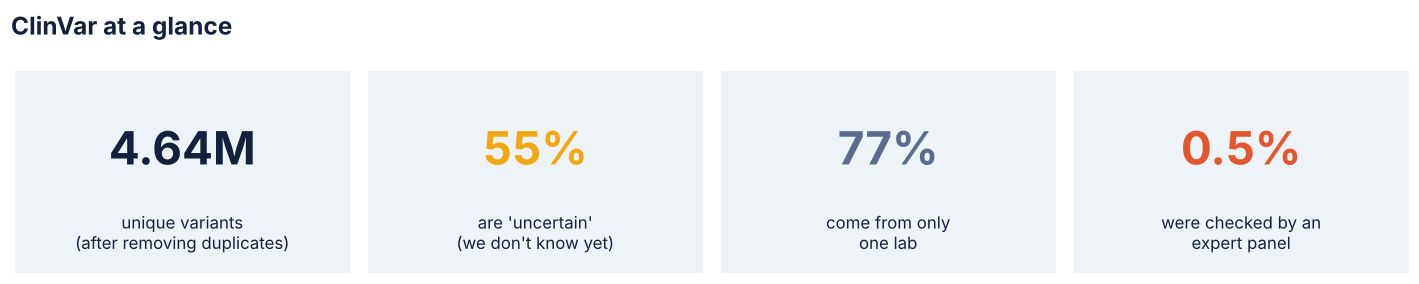

In [7]:
# @title Key numbers
share = labeled["Group"].value_counts(normalize=True) * 100
tiles = [
    (fmt(stats["unique_variants"]), "unique variants\n(after removing duplicates)", INK),
    (f"{share['VUS']:.0f}%", "are 'uncertain'\n(we don't know yet)", COLORS["VUS"]),
    (f"{(df['NumberSubmitters'] == 1).mean()*100:.0f}%", "come from only\none lab", MUTED),
    (f"{(df['Stars'] >= 3).mean()*100:.1f}%", "were checked by an\nexpert panel", COLORS["P/LP"]),
]
fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, (big, label, color) in zip(axes, tiles):
    ax.set_facecolor("#EEF3F7"); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.text(0.5, 0.62, big, ha="center", va="center", fontsize=30, fontweight="bold", color=color, transform=ax.transAxes)
    ax.text(0.5, 0.2, label, ha="center", va="center", fontsize=11, color=INK, transform=ax.transAxes)
fig.suptitle("ClinVar at a glance", x=0.01, ha="left", fontsize=16, fontweight="bold", color=INK)
plt.tight_layout(); plt.show()

## 2 · The data is messy

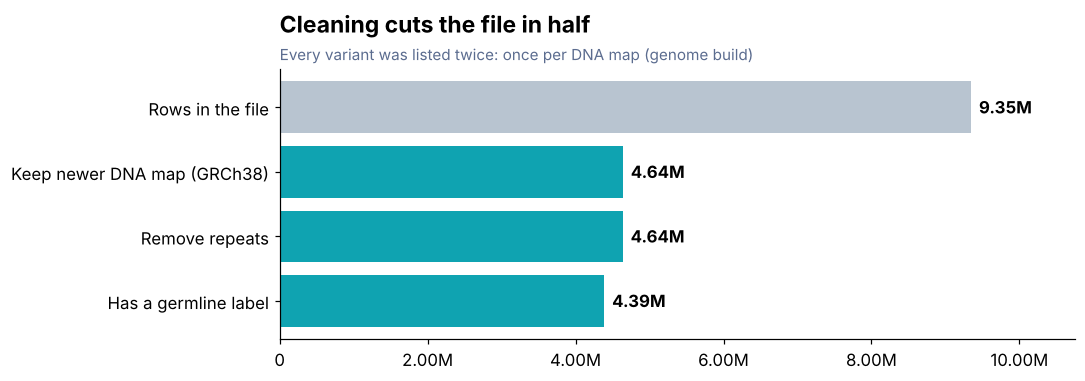

In [8]:
# @title Chart: cleaning funnel
steps = [("Rows in the file", stats["rows_in_file"]),
         ("Keep newer DNA map (GRCh38)", stats["rows_grch38"]),
         ("Remove repeats", stats["unique_variants"]),
         ("Has a germline label", stats["germline_labeled"])]
fig, ax = plt.subplots(figsize=(10, 3.6))
labels, vals = zip(*steps)
bars = ax.barh(labels[::-1], vals[::-1], color=["#0FA3B1", "#0FA3B1", "#0FA3B1", "#B8C4D0"])
for b, v in zip(bars, vals[::-1]):
    ax.text(v, b.get_y() + b.get_height()/2, f"  {fmt(v)}", va="center", fontweight="bold")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: fmt(x)))
ax.set_xlim(0, stats["rows_in_file"] * 1.15)
headline(ax, "Cleaning cuts the file in half", "Every variant was listed twice: once per DNA map (genome build)")
plt.tight_layout(); plt.show()

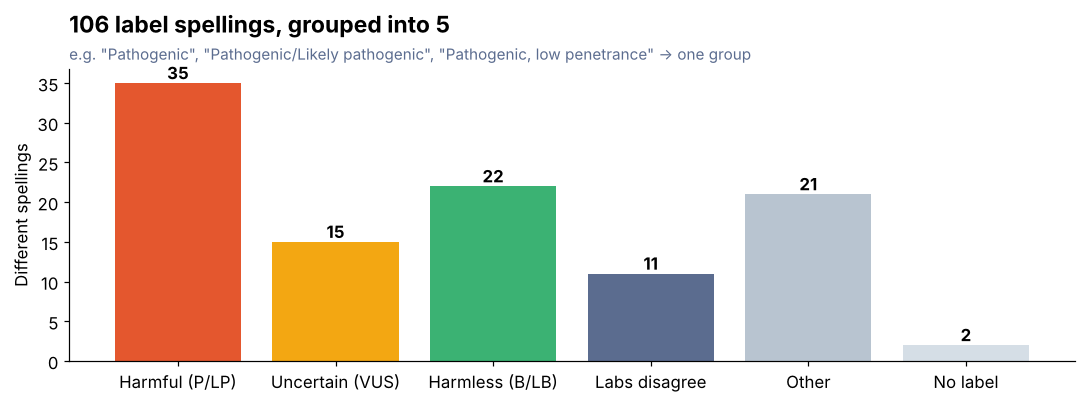

In [9]:
# @title Chart: label spellings
spell = pd.Series({lab: label_map.get(lab, "No label") for lab in raw_labels.index}).value_counts()
spell = spell.reindex(ORDER + ["No label"]).dropna()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar([NAMES.get(g, g) for g in spell.index], spell.values,
       color=[COLORS.get(g, "#D5DEE6") for g in spell.index])
for i, v in enumerate(spell.values):
    ax.text(i, v + 0.5, int(v), ha="center", fontweight="bold")
ax.set_ylabel("Different spellings")
headline(ax, f"{len(raw_labels)} label spellings, grouped into 5",
         'e.g. "Pathogenic", "Pathogenic/Likely pathogenic", "Pathogenic, low penetrance" -> one group')
plt.tight_layout(); plt.show()

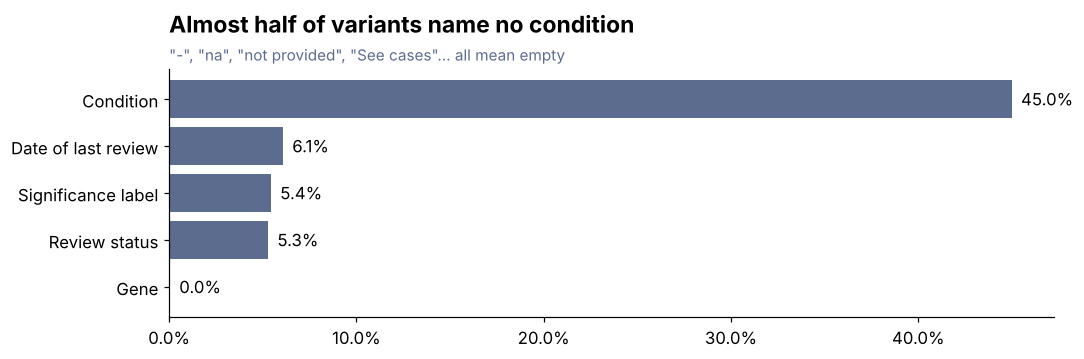

Note: 20% of individual condition entries just say 'not provided' / 'not specified'.


In [10]:
# @title Chart: missing data
labels_nice = {"LastEvaluated": "Date of last review", "ClinicalSignificance": "Significance label",
               "ReviewStatus": "Review status", "PhenotypeList": "Condition", "GeneSymbol": "Gene"}
mp = missing_pct.rename(labels_nice)[list(labels_nice.values())].sort_values()
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.barh(mp.index, mp.values, color=MUTED)
for i, v in enumerate(mp.values):
    ax.text(v, i, f"  {v:.1f}%", va="center")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
headline(ax, "Almost half of variants name no condition", '"-", "na", "not provided", "See cases"... all mean empty')
plt.tight_layout(); plt.show()

phen = explode(df["PhenotypeList"], "|")
placeholder = phen.str.lower().isin(["not provided", "not specified"]).mean() * 100
print(f"Note: {placeholder:.0f}% of individual condition entries just say 'not provided' / 'not specified'.")

## 3 · What we found

### Most variants are a mystery

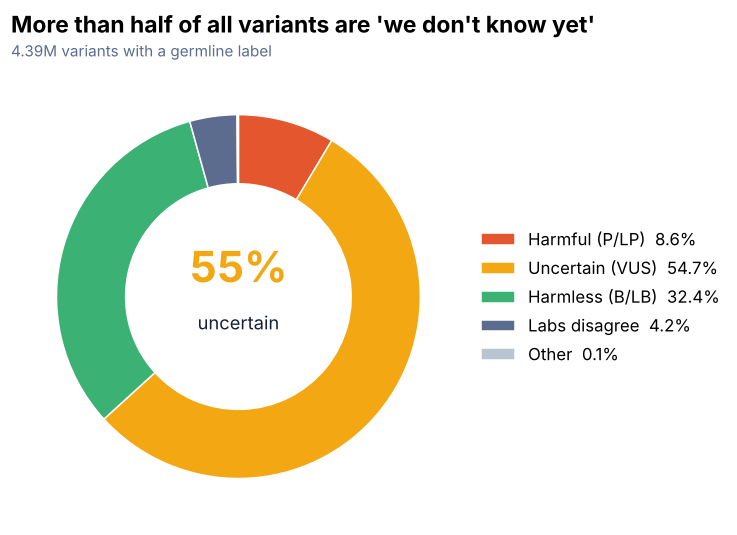

In [11]:
# @title Chart: label groups
share = labeled["Group"].value_counts(normalize=True).reindex(ORDER).fillna(0) * 100
fig, ax = plt.subplots(figsize=(9, 5))
wedges, _ = ax.pie(share, colors=[COLORS[g] for g in ORDER], startangle=90, counterclock=False,
                   wedgeprops=dict(width=0.38, edgecolor="white"))
ax.text(0, 0.08, f"{share['VUS']:.0f}%", ha="center", fontsize=28, fontweight="bold", color=COLORS["VUS"])
ax.text(0, -0.18, "uncertain", ha="center", fontsize=12, color=INK)
ax.legend(wedges, [f"{NAMES[g]}  {share[g]:.1f}%" for g in ORDER], loc="center left",
          bbox_to_anchor=(1, 0.5), frameon=False, fontsize=11)
headline(ax, "More than half of all variants are 'we don't know yet'",
         f"{fmt(len(labeled))} variants with a germline label")
plt.tight_layout(); plt.show()

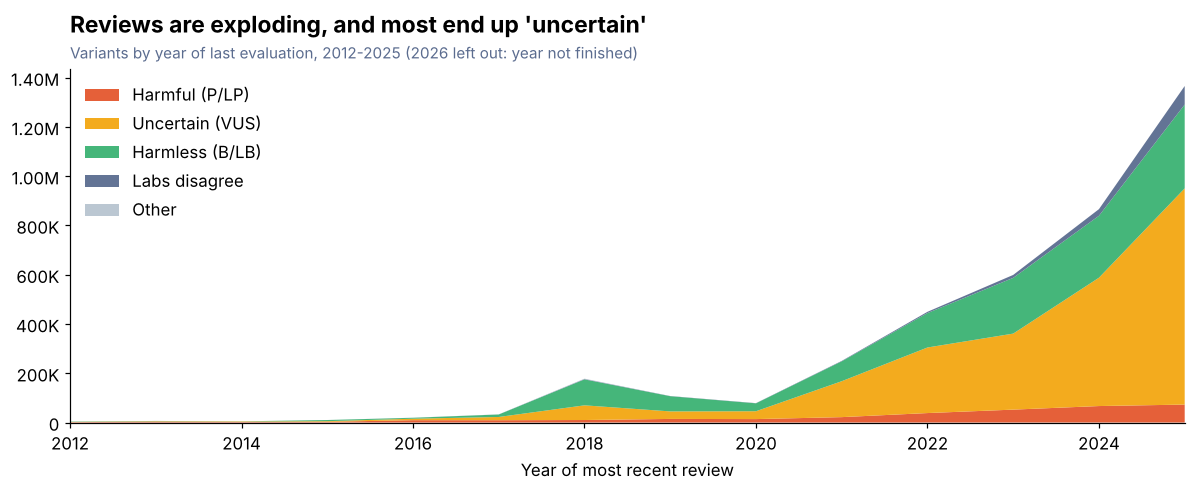

In [12]:
# @title Chart: reviews over time
yearly = (labeled[labeled["Year"].between(2012, 2025)]
          .groupby(["Year", "Group"], observed=True).size()
          .unstack(fill_value=0).reindex(columns=ORDER, fill_value=0))
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.stackplot(yearly.index, [yearly[g] for g in ORDER], colors=[COLORS[g] for g in ORDER],
             labels=[NAMES[g] for g in ORDER], alpha=0.95)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: fmt(x)))
ax.legend(loc="upper left", frameon=False)
ax.set_xlim(2012, 2025); ax.set_xlabel("Year of most recent review")
headline(ax, "Reviews are exploding, and most end up 'uncertain'",
         "Variants by year of last evaluation, 2012-2025 (2026 left out: year not finished)")
plt.tight_layout(); plt.show()

### Can we trust the labels?

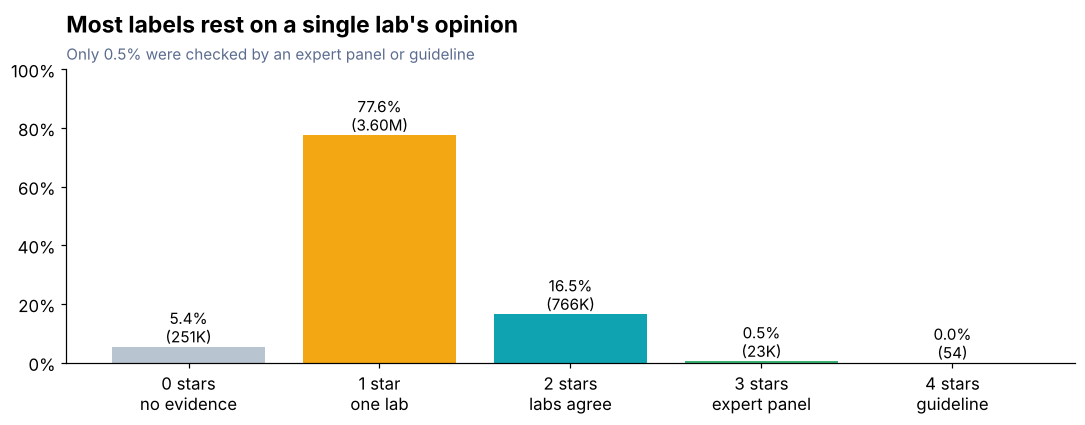

In [13]:
# @title Chart: review stars
sc = df["Stars"].value_counts().reindex(range(5), fill_value=0)
pct = sc / sc.sum() * 100
fig, ax = plt.subplots(figsize=(10, 4))
names = ["0 stars\nno evidence", "1 star\none lab", "2 stars\nlabs agree", "3 stars\nexpert panel", "4 stars\nguideline"]
bars = ax.bar(names, pct, color=["#B8C4D0", "#F3A712", "#0FA3B1", "#3BB273", "#14213D"])
for b, p, n in zip(bars, pct, sc):
    ax.text(b.get_x() + b.get_width()/2, p + 1.5, f"{p:.1f}%\n({fmt(n)})", ha="center", fontsize=10)
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_ylim(0, 100)
headline(ax, "Most labels rest on a single lab's opinion",
         f"Only {(df['Stars'] >= 3).mean()*100:.1f}% were checked by an expert panel or guideline")
plt.tight_layout(); plt.show()

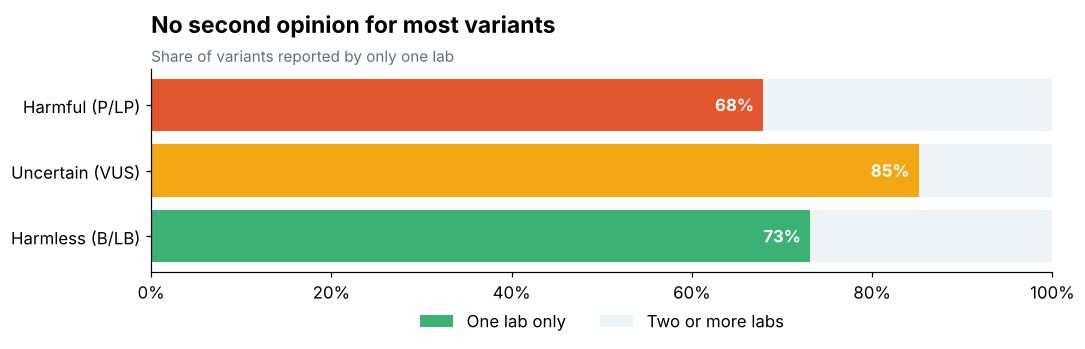

In [14]:
# @title Chart: one lab vs many
MAIN = ["P/LP", "VUS", "B/LB"]
single = (labeled.assign(one=labeled["NumberSubmitters"] == 1)
          .groupby("Group", observed=True)["one"].mean().reindex(MAIN) * 100)
fig, ax = plt.subplots(figsize=(10, 3.4))
y = [NAMES[g] for g in MAIN][::-1]
ax.barh(y, single[::-1], color=[COLORS[g] for g in MAIN][::-1], label="One lab only")
ax.barh(y, 100 - single[::-1], left=single[::-1], color="#EEF3F7", label="Two or more labs")
for i, v in enumerate(single[::-1]):
    ax.text(v - 1, i, f"{v:.0f}%", ha="right", va="center", color="white", fontweight="bold")
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_xlim(0, 100)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
headline(ax, "No second opinion for most variants", "Share of variants reported by only one lab")
plt.tight_layout(); plt.show()

### Where experts disagree

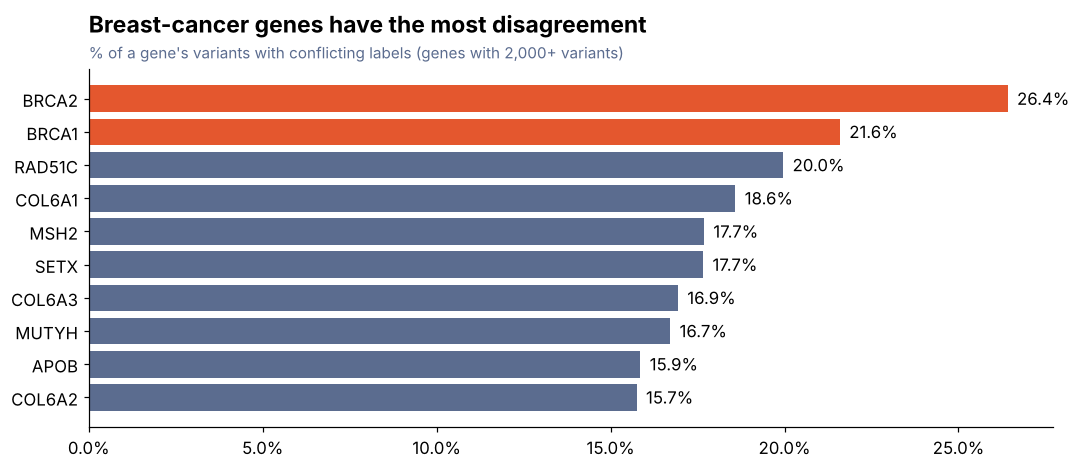

In [15]:
# @title Chart: conflicting genes
genes = labeled[["GeneSymbol", "Group"]].dropna()
genes = genes.assign(GeneSymbol=genes["GeneSymbol"].str.split(";")).explode("GeneSymbol")
gt = genes.groupby("GeneSymbol")["Group"].value_counts().unstack(fill_value=0)
gt["n"] = gt.sum(axis=1)
big = gt[gt["n"] >= 2000]   # only genes with enough variants to compare fairly
conf = (big["Conflicting"] / big["n"] * 100).sort_values().tail(10)
fig, ax = plt.subplots(figsize=(10, 4.4))
cols = [COLORS["P/LP"] if g in ("BRCA1", "BRCA2") else COLORS["Conflicting"] for g in conf.index]
ax.barh(conf.index, conf.values, color=cols)
for i, v in enumerate(conf.values):
    ax.text(v, i, f"  {v:.1f}%", va="center")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
headline(ax, "Breast-cancer genes have the most disagreement",
         "% of a gene's variants with conflicting labels (genes with 2,000+ variants)")
plt.tight_layout(); plt.show()

### Which genes and changes matter

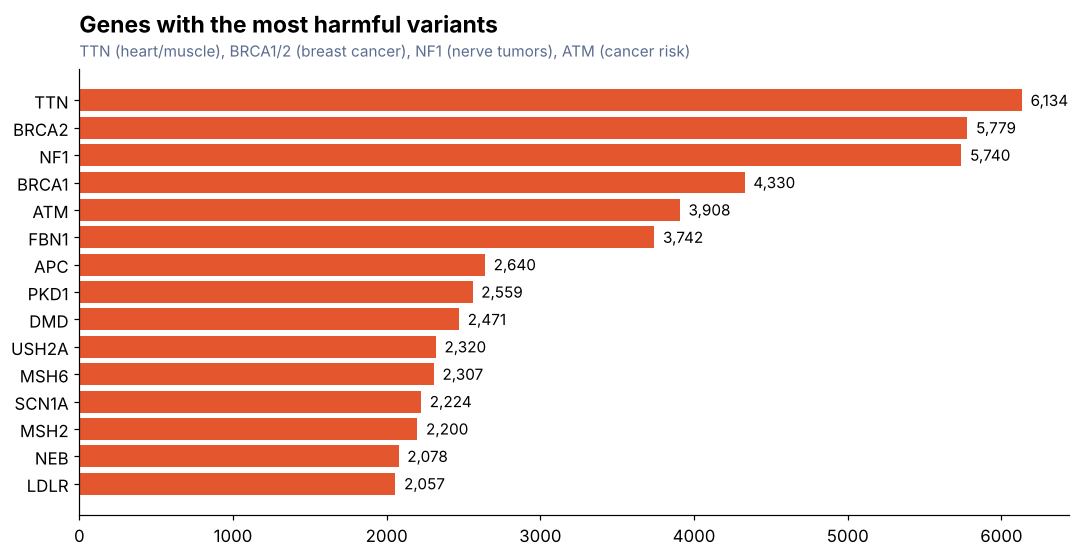

In [16]:
# @title Chart: top harmful genes
plp = explode(labeled.loc[labeled["Group"] == "P/LP", "GeneSymbol"], ";")
top = plp.value_counts().head(15).sort_values()
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.barh(top.index, top.values, color=COLORS["P/LP"])
for i, v in enumerate(top.values):
    ax.text(v, i, f"  {v:,}", va="center", fontsize=10)
headline(ax, "Genes with the most harmful variants",
         "TTN (heart/muscle), BRCA1/2 (breast cancer), NF1 (nerve tumors), ATM (cancer risk)")
plt.tight_layout(); plt.show()

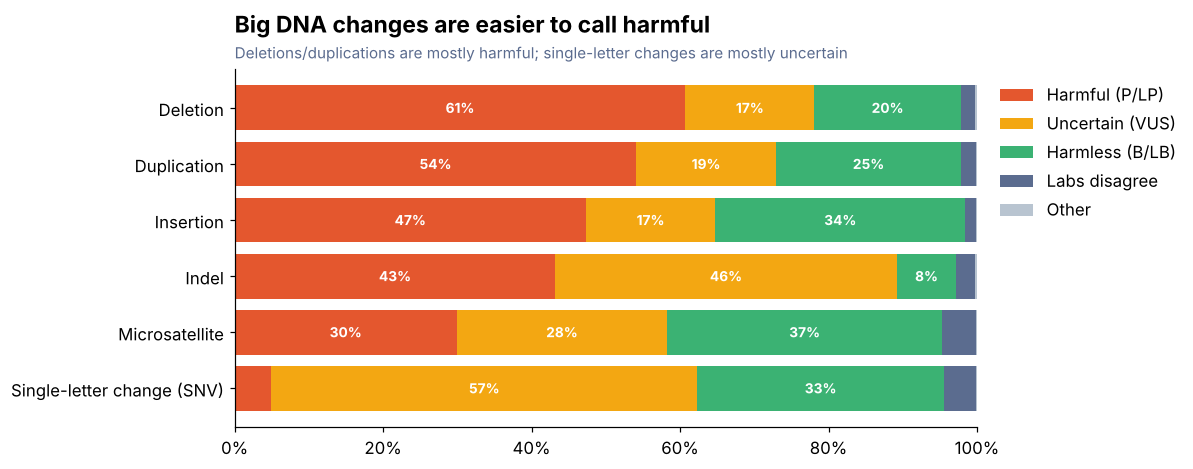

In [17]:
# @title Chart: variant type
top_types = labeled["Type"].value_counts().head(6).index
sub = labeled[labeled["Type"].isin(top_types)]
ct = (pd.crosstab(sub["Type"].astype(str), sub["Group"], normalize="index") * 100).reindex(columns=ORDER).fillna(0)
ct = ct.rename(index={"single nucleotide variant": "Single-letter change (SNV)"}).sort_values("P/LP")
fig, ax = plt.subplots(figsize=(11, 4.4))
left = np.zeros(len(ct))
for g in ORDER:
    ax.barh(ct.index, ct[g], left=left, color=COLORS[g], label=NAMES[g])
    for i, (l, v) in enumerate(zip(left, ct[g])):
        if v > 7: ax.text(l + v/2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    left += ct[g].values
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_xlim(0, 100)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
headline(ax, "Big DNA changes are easier to call harmful",
         "Deletions/duplications are mostly harmful; single-letter changes are mostly uncertain")
plt.tight_layout(); plt.show()

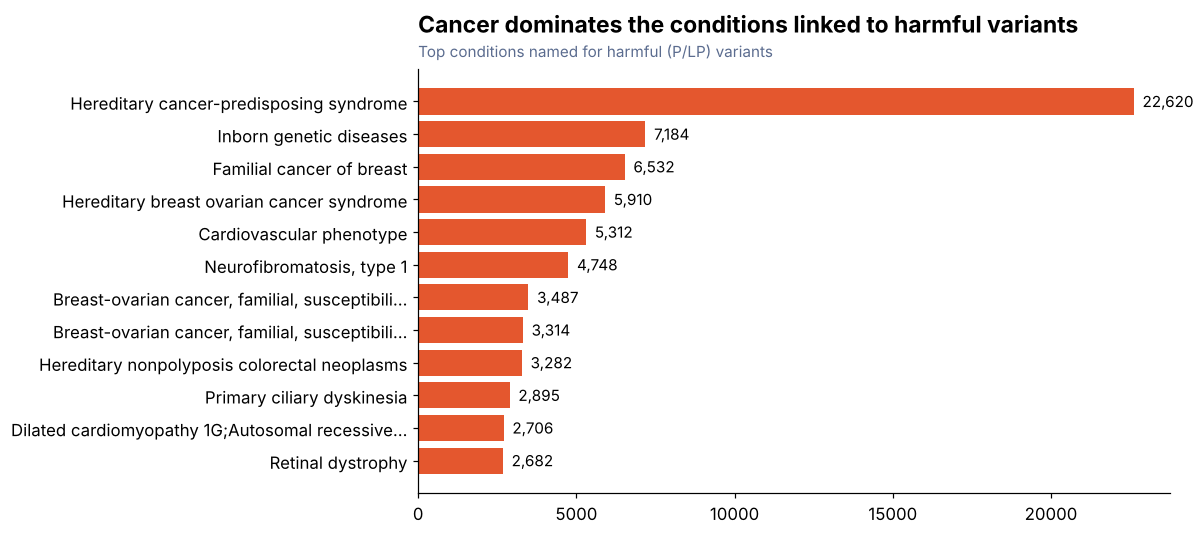

In [18]:
# @title Chart: conditions
ph = explode(labeled.loc[labeled["Group"] == "P/LP", "PhenotypeList"], "|")
ph = ph[~ph.str.lower().isin(["not provided", "not specified", "see cases"])]
top = ph.value_counts().head(12).sort_values()
names = [t if len(t) <= 48 else t[:45] + "..." for t in top.index]
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(range(len(top)), top.values, color=COLORS["P/LP"])
ax.set_yticks(range(len(top)), names)
for i, v in enumerate(top.values):
    ax.text(v, i, f"  {v:,}", va="center", fontsize=10)
headline(ax, "Cancer dominates the conditions linked to harmful variants",
         "Top conditions named for harmful (P/LP) variants")
plt.tight_layout(); plt.show()

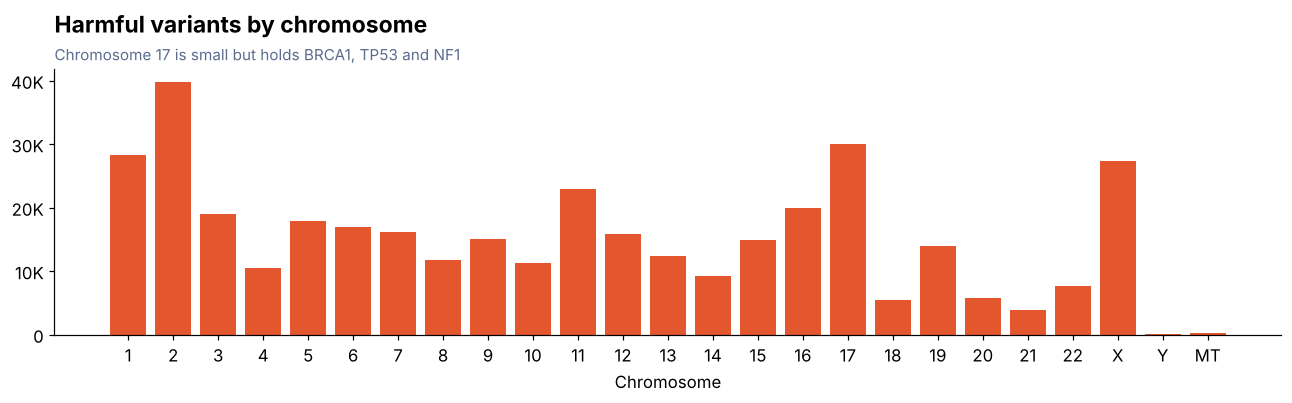

In [19]:
# @title Chart: chromosomes
order = [str(i) for i in range(1, 23)] + ["X", "Y", "MT"]
chrom = labeled.groupby("Chromosome", observed=True)["Group"].apply(lambda s: (s == "P/LP").sum())
chrom = chrom.reindex(order).fillna(0)
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(chrom.index, chrom.values, color=COLORS["P/LP"])
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: fmt(x)))
ax.set_xlabel("Chromosome")
headline(ax, "Harmful variants by chromosome", "Chromosome 17 is small but holds BRCA1, TP53 and NF1")
plt.tight_layout(); plt.show()

## 4 · Key takeaways

1. **We still don't know most of it.** More than half of labeled variants are "uncertain" (VUS).
2. **Trust varies a lot.** About 3 in 4 variants come from one lab only; under 1% were checked by an expert panel.
3. **Experts disagree most where it matters.** BRCA1/BRCA2, the best-known breast-cancer genes, have the highest conflict rates.
4. **Big DNA changes are easier to judge.** Deletions and duplications are mostly harmful; single-letter changes are mostly uncertain.
5. **The data needs cleaning before any of this is visible.** Duplicate rows, 100+ label spellings and hidden missing values.

*Patterns in a public database, not medical advice.*